# Enabling GPU

In [1]:
import keras
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')

if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print("GPU is available!")
else:
    print("No GPU detected!")

I0000 00:00:1793135272.636437  180007 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793135272.849063  180007 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793135274.562802  180007 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU is available!


W0000 00:00:1793135276.870145  180007 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


In [2]:
print("Keras backend:", keras.backend.backend())
print("GPU:", tf.config.list_physical_devices('GPU'))

Keras backend: tensorflow
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Import

In [3]:
# General
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Keras
import keras
from keras.models import Sequential
from keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)

# Optimizer
from keras.optimizers import Adam

# Callbacks
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
keras.utils.set_random_seed(42)

# Reading Data

In [4]:
train_ds, val_ds = keras.utils.image_dataset_from_directory("train", validation_split=0.2, subset="both", seed=42,
                                                            image_size=(48, 48), color_mode="grayscale", batch_size=32,
                                                            label_mode="int")

test_ds = keras.utils.image_dataset_from_directory("test", image_size=(48, 48), color_mode="grayscale", batch_size=32, label_mode="int", shuffle=False)

Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Using 5741 files for validation.


W0000 00:00:1793135385.571502  180007 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1793135385.701024  180007 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9217 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070, pci bus id: 0000:02:00.0, compute capability: 12.0a


Found 7178 files belonging to 7 classes.


# EDA

In [5]:
class_names = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

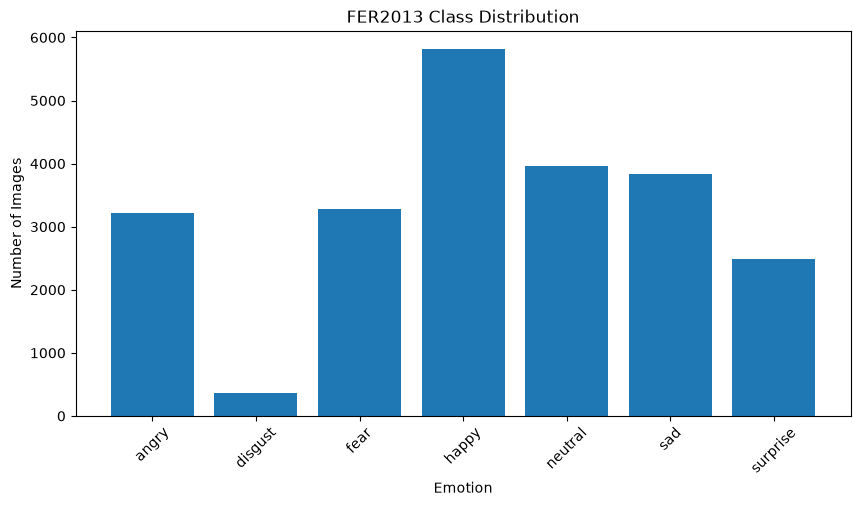

In [6]:
from collections import Counter
import matplotlib.pyplot as plt

# Count labels
labels = []

for X, y in train_ds:
    labels.extend(y.numpy())

counts = Counter(labels)

# Plot distribution
plt.figure(figsize=(10, 5))
plt.bar(class_names, [counts[i] for i in range(len(class_names))])

plt.xlabel('Emotion')
plt.ylabel('Number of Images')
plt.title('FER2013 Class Distribution')
plt.xticks(rotation=45)
plt.show()

In [7]:
for i, name in enumerate(class_names):
    print(f"{name}: {counts[i]}")

angry: 3218
disgust: 363
fear: 3285
happy: 5813
neutral: 3965
sad: 3834
surprise: 2490


# Preprocessing

In [8]:
train_ds = train_ds.map(lambda X, y: (X / 255.0, y))
val_ds = val_ds.map(lambda X, y: (X / 255.0, y))
test_ds = test_ds.map(lambda X, y: (X / 255.0, y))

In [29]:
train_ds = train_ds.unbatch().batch(128)
val_ds = val_ds.unbatch().batch(128)
test_ds = test_ds.unbatch().batch(128)

# Base Model

In [30]:
model = Sequential([Input(shape=(48, 48, 1)),
                    Conv2D(10, (3, 3), activation='relu'),
                    MaxPooling2D((2, 2)),
                    Conv2D(20, (3, 3), activation='relu'),
                    MaxPooling2D((2, 2)),
                    Flatten(),
                    Dense(64, activation='relu'),
                    Dense(32, activation='relu'),
                    Dense(10, activation='softmax')])


model.compile(loss = 'sparse_categorical_crossentropy',
              metrics = ['accuracy'])



history = model.fit(train_ds, validation_data=val_ds, epochs=3)

Epoch 1/3


I0000 00:00:1793137902.165241  237190 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_22', 16 bytes spill stores, 16 bytes spill loads

I0000 00:00:1793137903.585495  237197 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_8', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1793137903.731155  237189 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_8', 4 bytes spill stores, 4 bytes spill loads



    159/Unknown 3s 2ms/step - accuracy: 0.2641 - loss: 1.8061

I0000 00:00:1793137905.341084  237847 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1793137905.670937  237862 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1793137906.130460  237850 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_22', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1793137906.702026  237862 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_6', 8 bytes spill stores, 8 bytes spill loads



    180/Unknown 6s 16ms/step - accuracy: 0.2690 - loss: 1.7963

...

I0000 00:00:1793137909.341023  238456 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 3335684252158895386
I0000 00:00:1793137909.341063  238456 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 7437371737926886523


180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3497 - loss: 1.6531 - val_accuracy: 0.3372 - val_loss: 1.6654
Epoch 3/3
 22/180 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3786 - loss: 1.5975 

I0000 00:00:1793137909.783815  237179 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 3335684252158895386
I0000 00:00:1793137909.783843  237179 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 7437371737926886523
I0000 00:00:1793137909.880013  238456 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 3335684252158895386
I0000 00:00:1793137909.880056  238456 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 7437371737926886523


180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3890 - loss: 1.5792 - val_accuracy: 0.3944 - val_loss: 1.5660


I0000 00:00:1793137910.320518  237179 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 3335684252158895386
I0000 00:00:1793137910.320549  237179 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 7437371737926886523
I0000 00:00:1793137910.420005  238456 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 3335684252158895386
I0000 00:00:1793137910.420034  238456 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 7437371737926886523


<Axes: >

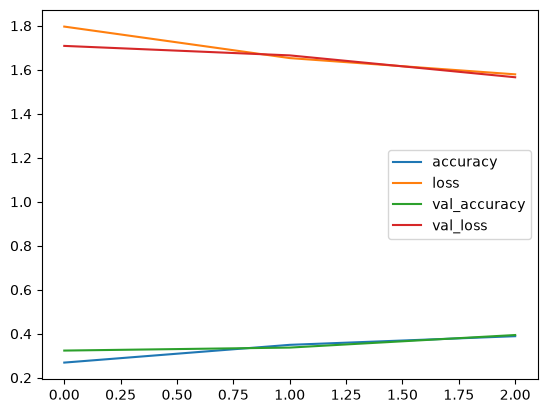

In [31]:
pd.DataFrame(history.history).plot()

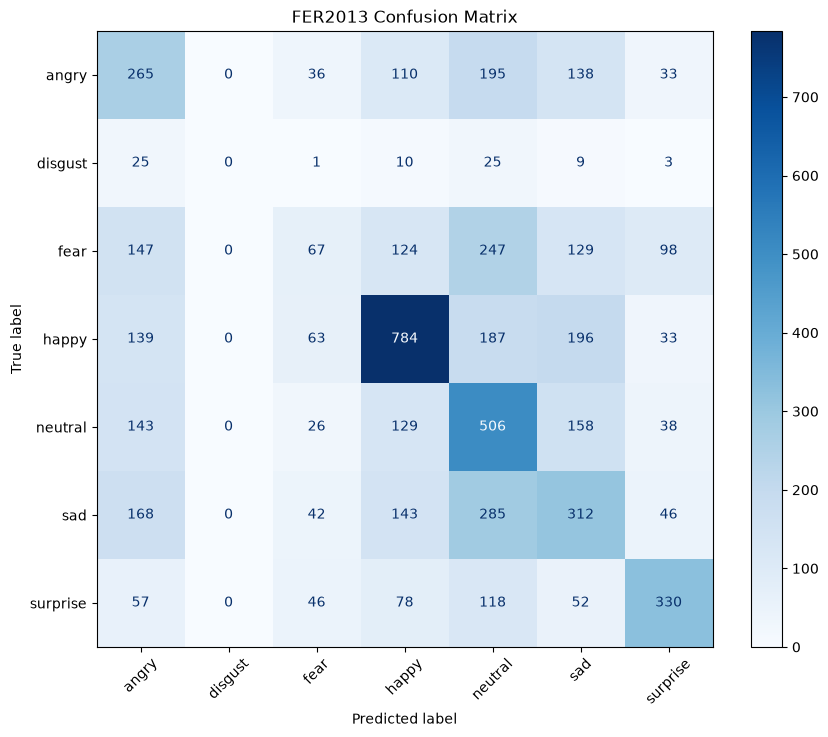

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

# Get actual labels and predictions
y_true = []
y_pred = []

for X, y in val_ds:
    predictions = model.predict(X, verbose=0)
    y_true.extend(y.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))


cm = confusion_matrix(y_true, y_pred)


disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('FER2013 Confusion Matrix')
plt.xticks(rotation=45)
plt.show()

# Balancing Classes

In [33]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

y_train = np.concatenate([y.numpy() for X, y in train_ds])

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes.tolist(), weights.tolist()))

print(class_weights)

{0: 1.0196217703986505, 1: 9.03896103896104, 2: 0.998825831702544, 3: 0.5644491410877098, 4: 0.8275265717888669, 5: 0.8558014755197854, 6: 1.3177280550774526}


In [34]:
from keras import Sequential, Input
from keras.layers import (
    Conv2D, MaxPooling2D, BatchNormalization,
    Dropout, Dense, GlobalAveragePooling2D,
    RandomFlip, RandomRotation, RandomZoom
)
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau



model = Sequential([
    Input(shape=(48, 48, 1)),

    # Data augmentation
    RandomFlip("horizontal"),
    RandomRotation(0.05),
    RandomZoom(0.1),

    # Block 1
    Conv2D(32, (3, 3), padding='same', activation='relu'),
    BatchNormalization(),
    Conv2D(32, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.2),

    # Block 2
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    BatchNormalization(),
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.3),

    # Block 3
    Conv2D(128, (3, 3), padding='same', activation='relu'),
    BatchNormalization(),
    Conv2D(128, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.3),

    # Classification
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.4),
    Dense(7, activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
# Callbacks
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=4,
    min_lr=0.00001,
    verbose=1
)

# Train
with tf.device('/GPU:0'):
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=100,
        callbacks=[early_stop, reduce_lr],
        batch_size=128
    )

Epoch 1/100


/home/yaser/ML_Projects/keras_gpu/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1793137928.958217  180007 meta_optimizer.cc:996] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_7_1/dropout_8_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


    180/Unknown 7s 28ms/step - accuracy: 0.2580 - loss: 1.7961

I0000 00:00:1793137934.556939  241098 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 7011366256334691163
I0000 00:00:1793137934.556976  241098 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 12159780485241532419
I0000 00:00:1793137934.556979  241098 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 18250746969332587461
/home/yaser/ML_Projects/keras_gpu/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


180/180 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - accuracy: 0.2580 - loss: 1.7961 - val_accuracy: 0.2442 - val_loss: 2.1877 - learning_rate: 0.0010
Epoch 2/100
  6/180 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.3190 - loss: 1.6795

...

I0000 00:00:1793138135.629263  241125 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 9069149456585856808
I0000 00:00:1793138135.629287  241125 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 6275276614752916038
I0000 00:00:1793138135.629291  241125 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 14979334569472118693


178/180 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6440 - loss: 0.9559

I0000 00:00:1793138140.252562  241098 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 18250746969332587461



Epoch 43: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
180/180 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.6449 - loss: 0.9545 - val_accuracy: 0.6262 - val_loss: 1.0067 - learning_rate: 1.2500e-04


I0000 00:00:1793138140.515511  241125 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 9069149456585856808
I0000 00:00:1793138140.515536  241125 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 6275276614752916038
I0000 00:00:1793138140.515538  241125 local_rendezvous.cc:486] Local rendezvous send item cancelled. Key hash: 3268618756192880292
I0000 00:00:1793138140.515543  241125 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 14979334569472118693


<Axes: >

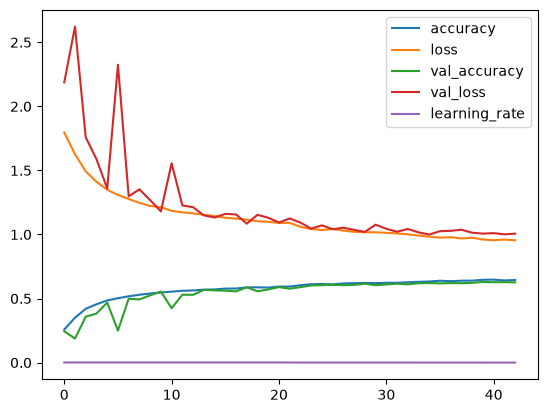

In [35]:
pd.DataFrame(history.history).plot()

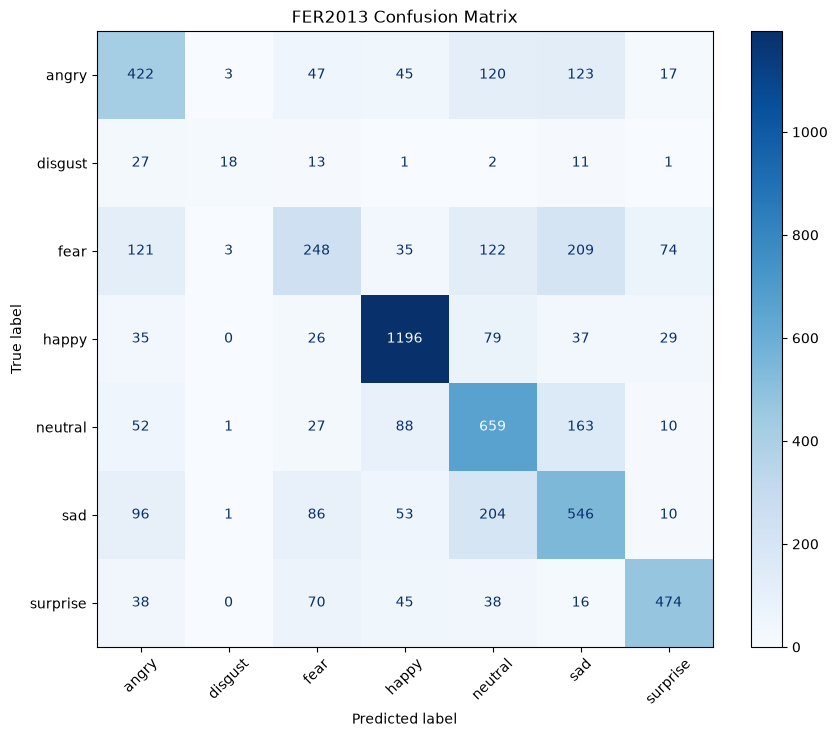

In [36]:
y_true = []
y_pred = []

for X, y in val_ds:
    predictions = model.predict(X, verbose=0)
    y_true.extend(y.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))


cm = confusion_matrix(y_true, y_pred)


disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('FER2013 Confusion Matrix')
plt.xticks(rotation=45)
plt.show()

# Evaluating

In [37]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6298 - loss: 0.9879
Test Loss: 0.9879
Test Accuracy: 62.98%


I0000 00:00:1793138192.083204  241125 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 9069149456585856808
I0000 00:00:1793138192.083240  241125 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 6275276614752916038
I0000 00:00:1793138192.083243  241125 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 14979334569472118693
/home/yaser/ML_Projects/keras_gpu/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


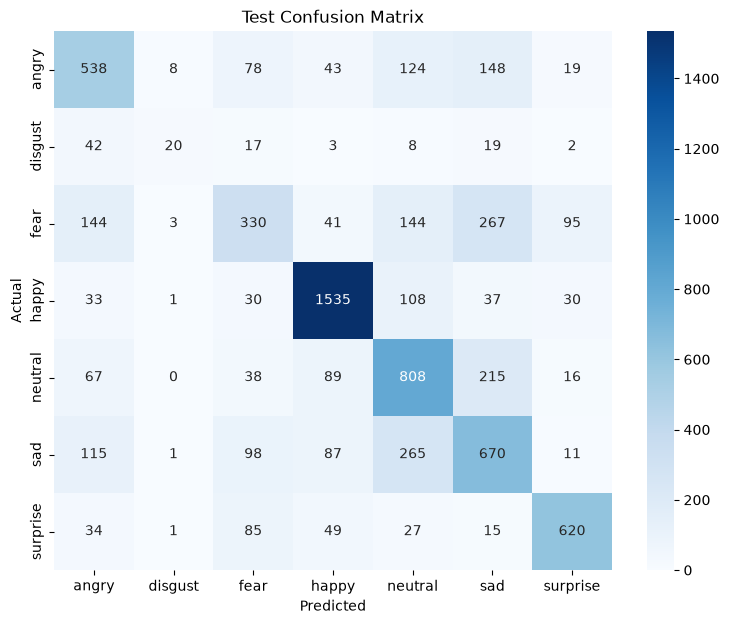

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Get actual labels and predictions
y_true = np.concatenate([y.numpy() for X, y in test_ds])

y_pred = model.predict(test_ds)
y_pred = np.argmax(y_pred, axis=1)

# Class names
class_names = [
    'angry', 'disgust', 'fear', 'happy',
    'neutral', 'sad', 'surprise'
]

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Test Confusion Matrix')
plt.show()

In [39]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

       angry       0.55      0.56      0.56       958
     disgust       0.59      0.18      0.28       111
        fear       0.49      0.32      0.39      1024
       happy       0.83      0.87      0.85      1774
     neutral       0.54      0.66      0.59      1233
         sad       0.49      0.54      0.51      1247
    surprise       0.78      0.75      0.76       831

    accuracy                           0.63      7178
   macro avg       0.61      0.55      0.56      7178
weighted avg       0.63      0.63      0.62      7178



# Saving Model

In [40]:
model.save("emotion_model.keras")

In [41]:
from keras.models import load_model

loaded_model = load_model("emotion_model.keras")

loaded_model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_2 (RandomFlip)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 913,335 (3.48 MB)

 Trainable params: 304,295 (1.16 MB)

 Non-trainable params: 448 (1.75 KB)

 Optimizer params: 608,592 (2.32 MB)

In [42]:
loaded_model.evaluate(test_ds)

57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6298 - loss: 0.9879


I0000 00:00:1793138271.404172  245384 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 9069149456585856808
I0000 00:00:1793138271.404236  245384 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 6275276614752916038
I0000 00:00:1793138271.404242  245384 local_rendezvous.cc:482] Local rendezvous recv item cancelled. Key hash: 14979334569472118693
/home/yaser/ML_Projects/keras_gpu/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


[0.9879406094551086, 0.6298412084579468]